In [76]:
import pandas as pd
import sqlite3
con = sqlite3.connect("C:/Users/afnaa/OneDrive/Documents/OJT SEM 3/ipl-cricket-analytics/ipl-cricket-analytics/data/raw/ipl.db")
def q(sql):
    return pd.read_sql(sql,con)

In [77]:
q('''
SELECT name
FROM sqlite_master
WHERE type IN ('table','view')
ORDER BY name;
''')

,name
0,deliveries
1,matches
2,matches_clean
3,players
4,teams
5,v_deliveries_clean
6,v_match_totals
7,v_matches_clean
8,v_matches_pom
9,v_players_clean


In [78]:
q('''
WITH per_season AS(
     SELECT DISTINCT season,COUNT(*)AS matches
     FROM matches
     GROUP BY season
)
SELECT season,matches
FROM per_season
ORDER BY  matches DESC
LIMIT 3;
''')

,season,matches
0,2013,76
1,2012,74
2,2022,74


In [79]:
q('''
WITH per_season AS(
     SELECT DISTINCT season,COUNT(*)AS matches
     FROM matches
     GROUP BY season
)
SELECT COUNT(*)AS seasons,
MAX(matches)AS busiest
FROM per_season;
''')

,seasons,busiest
0,19,76


In [80]:
q('''
WITH total AS(
SELECT batter,SUM(batter_runs)AS runs
FROM deliveries
GROUP BY batter)
SELECT batter,runs,
    RANK() OVER (ORDER BY runs DESC) AS rk
FROM total
ORDER BY rk
LIMIT 5;
''')


,batter,runs,rk
0,V Kohli,9050,1
1,RG Sharma,7185,2
2,S Dhawan,6769,3
3,DA Warner,6567,4
4,KL Rahul,5668,5


#### JOIN+CTE+WINDOW FUNCTION

In [81]:
q('''
SELECT COUNT(*) AS before_join
FROM matches_clean;
''')

,before_join
0,1212


In [82]:
q('''
WITH ranked_venues AS(
    SELECT
      *,
      ROW_NUMBER()OVER(
           PARTITION BY venue
           ORDER BY venue_id
      )AS rn
      FROM venues
),
dedup_venues AS(
     SELECT *
     FROM ranked_venues
     WHERE rn =1
)
SELECT COUNT(*)AS after_join
FROM matches_clean m
LEFT JOIN dedup_venues v
    ON m.venue = v.venue;
    ''')

,after_join
0,1212


In [83]:
q('''
WITH first_innings AS(
    SELECT 
       match_id,
       SUM(total_runs) AS first_innings_total
    FROM deliveries
    WHERE innings = 1
    GROUP BY match_id
)
SELECT *
FROM  first_innings
LIMIT 10;
''')

,match_id,first_innings_total
0,335982,222
1,335983,240
2,335984,129
3,335985,165
4,335986,110
5,335987,166
6,335988,142
7,335989,208
8,335990,214
9,335991,182


In [84]:
q('''
SELECT match_id,innings,
    SUM(total_runs)AS check_total
FROM deliveries
WHERE match_id = 335982
  AND innings=1
GROUP BY match_id,innings;
''')

,match_id,innings,check_total
0,335982,1,222


In [85]:
q('''
SELECT match_id,innings,
    SUM(total_runs)AS check_total
FROM deliveries
WHERE innings = 1
  AND match_id IN (335982,335983,335984,335985,335986)
GROUP BY match_id
ORDER BY match_id;
''')

,match_id,innings,check_total
0,335982,1,222
1,335983,1,240
2,335984,1,129
3,335985,1,165
4,335986,1,110


In [86]:
q("""
SELECT
    match_id,
    innings,
    COUNT(DISTINCT batting_team) AS team_count
FROM deliveries
WHERE innings = 1
GROUP BY match_id, innings
HAVING COUNT(DISTINCT batting_team) <> 1;
""")

,match_id,innings,team_count


In [87]:
q("""
WITH first_innings AS (
SELECT
match_id,
batting_team AS innings1_batting_team,
SUM(total_runs) AS first_innings_total
FROM deliveries
WHERE innings = 1
GROUP BY match_id,batting_team
)
SELECT *
FROM first_innings
LIMIT 5;
""")

,match_id,innings1_batting_team,first_innings_total
0,335982,Kolkata Knight Riders,222
1,335983,Chennai Super Kings,240
2,335984,Rajasthan Royals,129
3,335985,Mumbai Indians,165
4,335986,Sunrisers Hyderabad,110


In [88]:
q("""
WITH first_innings AS (
SELECT
match_id,
batting_team AS innings1_batting_team,
SUM(total_runs) AS first_innings_total
FROM deliveries
WHERE innings = 1
GROUP BY match_id,batting_team
)
SELECT 
    m.match_id,
    m.season_year,
    f.innings1_batting_team,
    f.first_innings_total
FROM matches_clean m
LEFT JOIN first_innings f
    ON m.match_id = f.match_id
LIMIT 5;
""")


,match_id,season_year,innings1_batting_team,first_innings_total
0,335982,2008,Kolkata Knight Riders,222
1,1082591,2017,Sunrisers Hyderabad,207
2,1082592,2017,Mumbai Indians,184
3,1082593,2017,Gujarat Lions,183
4,1082594,2017,Rising Pune Supergiant,163


In [89]:
con.executescript("""
DROP VIEW IF EXISTS v_match_totals;
CREATE VIEW v_match_totals AS
WITH first_innings AS (
    SELECT 
        match_id,
        batting_team AS innings1_batting_team,
        SUM(total_runs) AS first_innings_total
    FROM deliveries
    WHERE innings = 1
    GROUP BY match_id, batting_team
)
SELECT 
    m.*,
    f.innings1_batting_team,
    f.first_innings_total
FROM matches_clean m
LEFT JOIN first_innings f
    ON m.match_id = f.match_id;""")
con.commit()

In [90]:
q('''
SELECT COUNT(*)AS total_rows
FROM v_match_totals;''')

,total_rows
0,1212


In [91]:
q('''
SELECT 
    season_year,
    COUNT(DISTINCT match_id) AS match_count
FROM matches_clean
GROUP BY season_year
ORDER BY season_year ASC;
''')

,season_year,match_count
0,2008,58
1,2009,57
2,2010,60
3,2011,73
4,2012,74
5,2013,76
6,2014,60
7,2015,59
8,2016,60
9,2017,59


In [92]:
q('''
WITH season_counts AS(
    SELECT
       season_year,
       COUNT(*)AS matches
    FROM matches_clean
    GROUP BY season_year)
SELECT
   season_year,
   matches,
   LAG(matches)OVER(
        ORDER BY season_year
    )AS previous_season_matches
FROM season_counts
ORDER BY season_year;
''')

,season_year,matches,previous_season_matches
0,2008,58,NaN
1,2009,57,58.0
2,2010,60,57.0
3,2011,73,60.0
4,2012,74,73.0
5,2013,76,74.0
6,2014,60,76.0
7,2015,59,60.0
8,2016,60,59.0
9,2017,59,60.0


In [93]:
q("""
WITH season_counts AS (
    SELECT
        season_year,
        COUNT(*) AS matches
    FROM matches_clean
    GROUP BY season_year
),
with_previous AS (
    SELECT
        season_year,
        matches,
        LAG(matches) OVER (
            ORDER BY season_year
        ) AS previous_season_matches
    FROM season_counts
)
SELECT
    season_year,
    matches,
    previous_season_matches,
    matches - previous_season_matches AS season_change
FROM with_previous
ORDER BY season_year;
""")

,season_year,matches,previous_season_matches,season_change
0,2008,58,NaN,NaN
1,2009,57,58.0,-1.0
2,2010,60,57.0,3.0
3,2011,73,60.0,13.0
4,2012,74,73.0,1.0
5,2013,76,74.0,2.0
6,2014,60,76.0,-16.0
7,2015,59,60.0,-1.0
8,2016,60,59.0,1.0
9,2017,59,60.0,-1.0


In [94]:
q('''
SELECT 
   MIN(over_number)AS min_over,
   MAX(over_number)AS max_over,
   COUNT(DISTINCT over_number)AS distinct_overs
FROM deliveries
WHERE is_super_over=0;''')

,min_over,max_over,distinct_overs
0,0,19,20


In [95]:
q('''
SELECT 
   ROUND(
     6.0 * SUM(total_runs) / COUNT(*),2
   ) AS powerplay_rpo
FROM deliveries
WHERE is_super_over=0
   AND is_wide_ball=0
   AND is_no_ball=0
   AND over_number BETWEEN 0 AND 5;
   ''')

,powerplay_rpo
0,7.71


In [96]:
q('''
SELECT 
   ROUND(
     6.0 * SUM(total_runs) / COUNT(*),2
   ) AS deathover_rpo
FROM deliveries
WHERE is_super_over=0
   AND is_wide_ball=0
   AND is_no_ball=0
   AND over_number BETWEEN 15 AND 19;
   ''')

,deathover_rpo
0,9.61


In [97]:
q('''
SELECT 
   ROUND(
     100.0 * SUM(is_wicket) / COUNT(*),2
   ) AS powerplay_wicket_rate
FROM deliveries
WHERE is_super_over=0
   AND is_wide_ball=0
   AND is_no_ball=0
   AND over_number BETWEEN 0 AND 5;
   ''')

,powerplay_wicket_rate
0,4.0


In [98]:
q('''SELECT 
   ROUND(
     100.0 * SUM(is_wicket) / COUNT(*),2
   ) AS deathover_rpo
FROM deliveries
WHERE is_super_over=0
   AND is_wide_ball=0
   AND is_no_ball=0
   AND over_number BETWEEN 15 AND 19;
   ''')

,deathover_rpo
0,8.41


do are harder to bowlbcz scoreing is higher & wickets also fall much more frequent

In [99]:
q('''
SELECT 
   ROUND(
     6.0 * SUM(total_runs) / COUNT(*),2
   ) AS deathover_rpo
FROM deliveries
WHERE is_super_over=0
   AND is_wide_ball=0
   AND is_no_ball=0
   AND over_number BETWEEN 6 AND 14;
   ''')

,deathover_rpo
0,7.67


In [100]:
q('''
SELECT 
   ROUND(
     100.0 * SUM(CASE WHEN batter_runs=0 THEN 1 ELSE 0 END)/ COUNT(*),2
   ) AS batter_dot
FROM deliveries
WHERE is_super_over=0
   AND is_wide_ball=0
   AND is_no_ball=0;
''')

,batter_dot
0,37.45


### venue analysis

In [101]:
q('''
SELECT
    venue_clean,
    COUNT(*) AS match_count
FROM matches_clean
GROUP BY venue_clean
ORDER BY match_count DESC
LIMIT 10;
''')                            

,venue_clean,match_count
0,Wankhede Stadium,130
1,M Chinnaswamy Stadium,104
2,Eden Gardens,104
3,MA Chidambaram Stadium,95
4,Rajiv Gandhi International Stadium,87
5,Sawai Mansingh Stadium,66
6,Feroz Shah Kotla,60
7,Dubai International Cricket Stadium,46
8,Arun Jaitley Stadium,41
9,Narendra Modi Stadium,37


###### 1.finding no? 
###### 130 matches at wankhede stadium
###### 2. 
###### 3. all matches in matches_clean
###### 4.  help ensure veneue level analysis and comparison are based on cleaned_venue names rather than fragmanted row names

### Toss winner also wins?

#### A match that enter with a clear winner = decisive match

In [102]:
q('''
SELECT COUNT(*)AS decisive_matchs,
SUM(CASE WHEN toss_winner=match_winner THEN 1 ELSE 0 END) AS toss_winner_won,
ROUND(100.0 * SUM(CASE WHEN toss_winner=match_winner THEN 1 ELSE 0 END)/ COUNT(*),2
)AS percentage
FROM matches_clean
WHERE result='win';
''')

,decisive_matchs,toss_winner_won,percentage
0,1187,613,51.64


##### 1.613 of 1187(51.64%)
##### 2.matches where toss_winner=matches_winner
##### 3.1187  decisive matches where result='win'
##### 4.help asses whether winning the tose is aasociated with a meaningful match winning advantage

### field-first trend

In [103]:
q("""
SELECT 
     season_year,
     COUNT(*) AS total_matches,
     SUM(CASE WHEN toss_decision = 'field' THEN 1 ELSE 0 END) AS field_first,
     ROUND(
        100.0 * SUM(CASE WHEN toss_decision = 'field' THEN 1 ELSE 0 END)
        / COUNT(*),
        2
     ) AS field_first_pct
FROM matches_clean
GROUP BY season_year
ORDER BY season_year;
""")

,season_year,total_matches,field_first,field_first_pct
0,2008,58,32,55.17
1,2009,57,22,38.60
2,2010,60,21,35.00
3,2011,73,48,65.75
4,2012,74,37,50.00
5,2013,76,31,40.79
6,2014,60,41,68.33
7,2015,59,34,57.63
8,2016,60,49,81.67
9,2017,59,48,81.36


###### 55.17,38.6 in 2009,35 in 2010,about 80 in 2016-2019
###### percent of matches in each season where the toss_winning team choose to field
###### all matches in each season in matches_clean
###### helps identify how toss strategy & preference for fielding first change over time

In [104]:
q('''
SELECT COUNT(*)AS caught_dismissals
FROM deliveries
WHERE wicket_kind='caught';''')

,caught_dismissals
0,9056


##### 9056
##### delivery record where wicket_kind='caught'
##### dismissal record in the delivery table
##### helps identify how imp caught dismissals are as a mode of taking wickets

In [105]:
q('''
SELECT COUNT(*) AS decisive_matches
FROM v_match_totals
WHERE result ='win'
  AND first_innings_total IS NOT NULL;
''')

,decisive_matches
0,1187


In [106]:
q('''
SELECT
    CASE
        WHEN first_innings_total < 140 THEN 'Under 140'
        WHEN first_innings_total BETWEEN 140 AND 159 THEN '140-159'
        WHEN first_innings_total BETWEEN 160 AND 179 THEN '160-179'
        WHEN first_innings_total BETWEEN 180 AND 199 THEN '180-199'
        ELSE '200+'
    END AS score_band,
    COUNT(*) AS matches
FROM v_match_totals
WHERE result = 'win'
    AND first_innings_total IS NOT NULL
GROUP BY score_band;
''')

,score_band,matches
0,140-159,241
1,160-179,312
2,180-199,217
3,200+,198
4,Under 140,219


In [107]:
q("""
SELECT 
    match_id,
    first_innings_total,
    innings1_batting_team,
    match_winner,
    CASE
        WHEN match_winner != innings1_batting_team THEN 1
        ELSE 0
    END AS chase_win
FROM v_match_totals
WHERE result = 'win'
     AND first_innings_total IS NOT NULL
LIMIT 10;
""")

,match_id,first_innings_total,innings1_batting_team,match_winner,chase_win
0,335982,222,Kolkata Knight Riders,Kolkata Knight Riders,0
1,1082591,207,Sunrisers Hyderabad,Sunrisers Hyderabad,0
2,1082592,184,Mumbai Indians,Rising Pune Supergiant,1
3,1082593,183,Gujarat Lions,Kolkata Knight Riders,1
4,1082594,163,Rising Pune Supergiant,Punjab Kings,1
5,1082595,157,Royal Challengers Bangalore,Royal Challengers Bangalore,0
6,1082596,135,Gujarat Lions,Sunrisers Hyderabad,1
7,1082597,178,Kolkata Knight Riders,Mumbai Indians,1
8,1082598,148,Royal Challengers Bangalore,Punjab Kings,1
9,1082599,205,Delhi Capitals,Delhi Capitals,0


In [108]:
q("""
WITH chase_data AS (
SELECT first_innings_total,
CASE
WHEN first_innings_total < 140 THEN 'Under 140'
WHEN first_innings_total BETWEEN 140 AND 159 THEN '140-159'
WHEN first_innings_total BETWEEN 160 AND 179 THEN '160-179'
WHEN first_innings_total BETWEEN 180 AND 199 THEN '180-199'
ELSE '200+' 
END AS score_band,

CASE WHEN match_winner != innings1_batting_team THEN 1 ELSE 0 END AS chase_win

FROM v_match_totals
WHERE result = 'win'
AND first_innings_total IS NOT NULL
)

SELECT
score_band,
COUNT(*) AS sample_size,
ROUND(
100.0 * SUM(chase_win) / COUNT(*),1) AS chase_win_rate

FROM chase_data
GROUP BY score_band
ORDER BY 
CASE score_band

WHEN 'Unde 140' THEN 1
WHEN '140-159' THEN 2
WHEN '160-179' THEN 3
WHEN '180-199' THEN 4
WHEN '200+' THEN 5
END;
""")

,score_band,sample_size,chase_win_rate
0,Under 140,219,82.6
1,140-159,241,71.0
2,160-179,312,53.2
3,180-199,217,38.2
4,200+,198,23.2


In [109]:
q("""
SELECT
    COUNT(*) AS matches,
    SUM(
        CASE WHEN win_by_wickets IS NOT NULL THEN 1 ELSE 0
        END
    ) AS chase_wins,
    ROUND(
        100.0 * SUM(
            CASE WHEN win_by_wickets IS NOT NULL THEN 1 ELSE 0
            END
        ) / COUNT(*),
        1
    ) AS chase_win_rate
FROM v_match_totals
WHERE result = 'win'
  AND first_innings_total < 140;
""")

,matches,chase_wins,chase_win_rate
0,219,177,80.8


In [110]:
q("""
WITH chase_defs AS (
    SELECT
        match_id,

        CASE
            WHEN match_winner != innings1_batting_team THEN 1
            ELSE 0
        END AS definition_1,

        CASE
            WHEN win_by_wickets IS NOT NULL THEN 1
            ELSE 0
        END AS definition_2

    FROM v_match_totals
    WHERE result = 'win'
      AND first_innings_total IS NOT NULL
)

SELECT
    COUNT(*) AS total_matches,
    SUM(
        CASE
            WHEN definition_1 = definition_2 THEN 1
            ELSE 0
        END
    ) AS agreements,
    SUM(
        CASE
            WHEN definition_1 != definition_2 THEN 1
            ELSE 0
        END
    ) AS disagreements,
    ROUND(
        100.0 * SUM(
            CASE
                WHEN definition_1 = definition_2 THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        1
    ) AS agreement_pct
FROM chase_defs;
""")

,total_matches,agreements,disagreements,agreement_pct
0,1187,1181,6,99.5


In [111]:
chase_bands = q("""
WITH chase_data AS (
    SELECT
        first_innings_total,

        CASE
            WHEN first_innings_total < 140 THEN 'Under 140'
            WHEN first_innings_total BETWEEN 140 AND 159 THEN '140-159'
            WHEN first_innings_total BETWEEN 160 AND 179 THEN '160-179'
            WHEN first_innings_total BETWEEN 180 AND 199 THEN '180-199'
            ELSE '200+'
        END AS score_band,

        CASE
            WHEN match_winner != innings1_batting_team THEN 1
            ELSE 0
        END AS chase_win

    FROM v_match_totals
    WHERE result = 'win'
      AND first_innings_total IS NOT NULL
)

SELECT
    score_band,
    COUNT(*) AS sample_size,
    ROUND(
        100.0 * SUM(chase_win) / COUNT(*),
        1
    ) AS chase_win_rate
FROM chase_data
GROUP BY score_band
ORDER BY
    CASE score_band
        WHEN 'Under 140' THEN 1
        WHEN '140-159' THEN 2
        WHEN '160-179' THEN 3
        WHEN '180-199' THEN 4
        WHEN '200+' THEN 5
    END;
""")

chase_bands

,score_band,sample_size,chase_win_rate
0,Under 140,219,82.6
1,140-159,241,71.0
2,160-179,312,53.2
3,180-199,217,38.2
4,200+,198,23.2


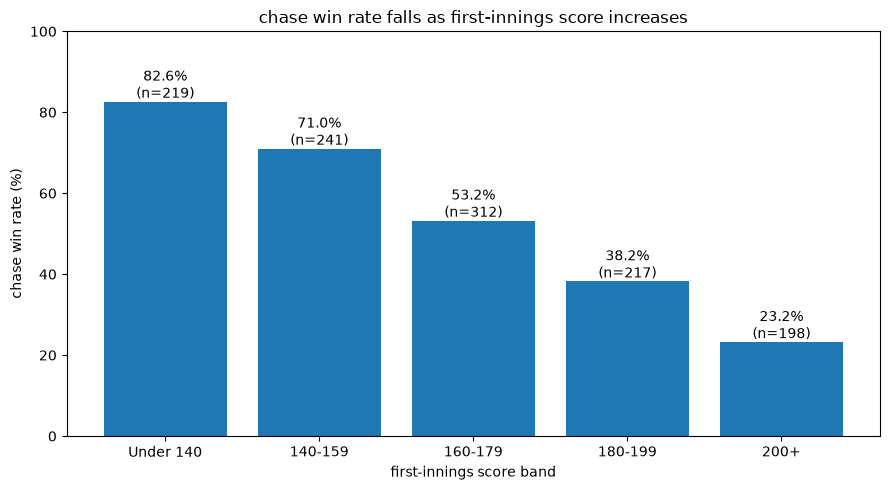

In [112]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9,5))
bars=plt.bar(
    chase_bands['score_band'],
    chase_bands['chase_win_rate'])
plt.title("chase win rate falls as first-innings score increases")
plt.xlabel("first-innings score band")
plt.ylabel("chase win rate (%)")
for bar,rate,n in zip(
    bars,
    chase_bands['chase_win_rate'],
    chase_bands['sample_size']):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height()+1,
        f"{rate}%\n(n={n})",
        ha='center')
plt.ylim(0,100)
plt.tight_layout()
plt.savefig("../reports/figures/chase_win_rate.png",dpi=300,bbox_inches="tight")
plt.show()

###### this code create a barchart showing how chase_win rate changes across different first innings score band.
###### matplotlib pyplot is imported as plt to create a chart, and fix size controls which chart size.plt.bar uses the score bands on this x axis & chase win rates on the y axis. 
###### the chart includes a clear title & lable axis with the percentage unit. a for loop with zip those through each bar & adds the win rate & sample size n about it.
###### plt.ylim(0,100): set the precentage scale from 0-100 , tight_layout : adjust the spacing,& plt.show():displys the cmplted  charts.

##### finding: higher first innings totals are ascscoiated with lower chase win rates
##### insights: highr first innings totals are ascscoiated with lower chase win rates, can use the pattern when deciding what total to target how to purseue additional runs

In [113]:
toss_chart = q("""
SELECT
    CASE
        WHEN toss_winner = match_winner
        THEN 'Toss Winner Won Match'
        ELSE 'Toss Winner Did Not Win'
    END AS outcome,
    COUNT(*) AS matches
FROM matches_clean
WHERE result = 'win'
GROUP BY outcome;
""")

toss_chart

,outcome,matches
0,Toss Winner Did Not Win,574
1,Toss Winner Won Match,613


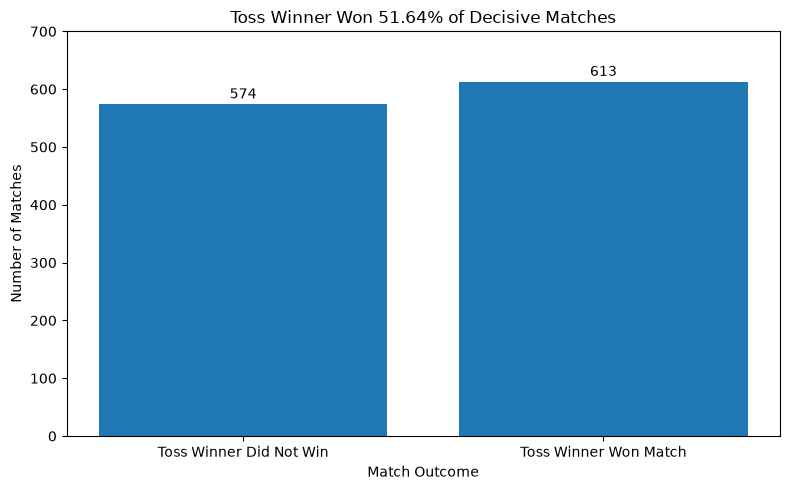

In [114]:
plt.figure(figsize=(8, 5))

bar = plt.bar(
    toss_chart['outcome'],
    toss_chart['matches']
)

plt.title('Toss Winner Won 51.64% of Decisive Matches')
plt.xlabel('Match Outcome')
plt.ylabel('Number of Matches')

for bar, value in zip(bar, toss_chart['matches']):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 10,
        f'{value}',
        ha='center'
    )

plt.ylim(0, 700)
plt.tight_layout()
plt.savefig("../reports/figures/toss_result.png",dpi=300,bbox_inches="tight")
plt.show()

In [115]:
field_first = q('''
SELECT
    season_year,
    COUNT(*)AS total_matches,
    SUM(CASE WHEN toss_decision='field' THEN 1 ELSE 0 END)AS field_first,
    ROUND(
       100.0* SUM(CASE WHEN toss_decision='field' THEN 1 ELSE 0 END)/ COUNT(*),2) AS field_first_pct
FROM matches_clean
GROUP BY season_year
ORDER BY season_year;''')
field_first

,season_year,total_matches,field_first,field_first_pct
0,2008,58,32,55.17
1,2009,57,22,38.60
2,2010,60,21,35.00
3,2011,73,48,65.75
4,2012,74,37,50.00
5,2013,76,31,40.79
6,2014,60,41,68.33
7,2015,59,34,57.63
8,2016,60,49,81.67
9,2017,59,48,81.36


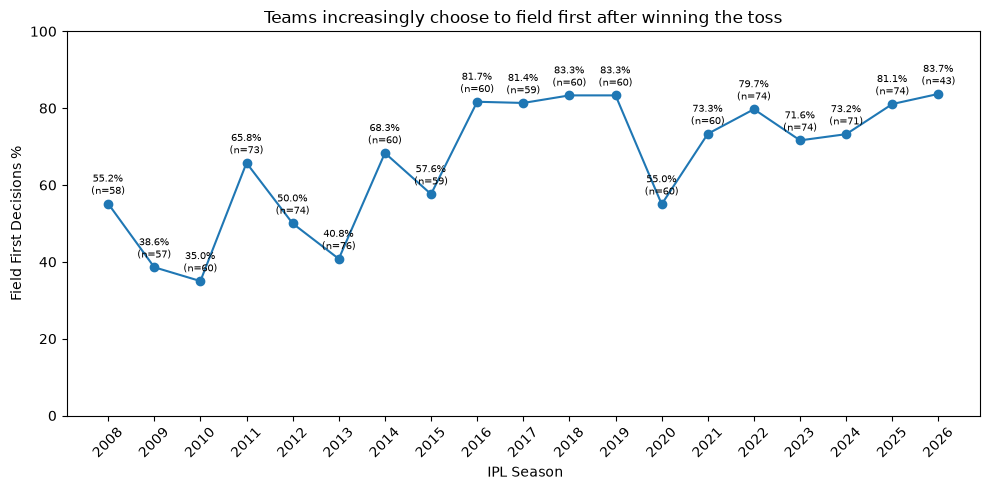

In [116]:
plt.figure(figsize=(10,5))

plt.plot(
    field_first['season_year'],
    field_first['field_first_pct'],
    marker='o'
)

plt.xlabel(' IPL Season')
plt.ylabel('Field First Decisions %')
plt.title('Teams increasingly choose to field first after winning the toss')

plt.xticks( field_first['season_year'],rotation=45)
for x,y,n in zip(
    field_first['season_year'],
    field_first['field_first_pct'],
    field_first['total_matches']
):
    plt.annotate(
        f"{y:.1f}%\n(n={n})",
        (x,y),
        textcoords='offset points',
        xytext=(0,7),
        ha="center",
        fontsize=7
    )
plt.ylim(0,100)
plt.tight_layout()
plt.savefig("../reports/figures/field_first_trend.png",dpi=300,bbox_inches="tight")
plt.show()

# **IPL Analysis Report**

### Insight 1 - First-Innings Total and Chase Success

##### The analysis shows that the chase win rate decreases as the first-innings score increases, falling from 82.6% for scores below 140 (n=219) to 23.2% for scores of 200 or more (n=198) across 1,187 decisive matches. This suggests that teams batting first can use higher first-innings totals to put greater pressure on the chasing team, with approximately 175 runs as a useful target to aim for. However, the analysis does not consider factors such as pitch conditions, player fitness, or injuries, which may also affect match outcomes. As a validation check, the 1,187 decisive matches identified in SQL were cross-checked in Excel, which also returned 1,187 matches.

### Insight 2-Toss Result and Match Success

##### The analysis shows that the toss winner also won the match in 613 out of 1,187 decisive matches (51.64%), while the toss winner did not win in 574 matches. This suggests that winning the toss alone does not show a strong advantage in determining the final match result, since the outcomes are nearly evenly split. Therefore, teams should not rely on the toss result alone when making match strategies and should also consider factors such as batting performance, bowling performance, and match conditions.

### Insight 3-Field First Decision Over Time

##### The analysis shows that the preference for fielding first after winning the toss increased over time. Field-first decisions were 55.17% in 2008, 38.60% in 2009, and 35.00% in 2010, while they exceeded 80% in each season from 2016 to 2019. This indicates a clear shift in team strategy toward choosing to chase during that period. Therefore, teams should consider the increasing preference for chasing when planning toss strategy, while also evaluating season and match conditions rather than assuming that fielding first is always the better option.

In [117]:
from pathlib import Path
report_path=Path("../reports/analysis_report.md")
report_path.touch(exist_ok=True)
print(report_path)

..\reports\analysis_report.md


In [118]:
report = """# IPL Analysis Report
This report presents key business insights from the cleaned IPL dataset.
## Insight 1 — First-Innings Total and Chase Success
The analysis shows that the chase win rate decreases as the first-innings score increases, falling from **82.6% for scores below 140 (n=219)** to **23.2% for scores of 200 or more (n=198)** across **1,187 decisive matches**. This suggests that teams batting first can use higher first-innings totals to put greater pressure on the chasing team, with approximately **175 runs as a useful target to aim for**. However, the analysis does not consider factors such as **pitch conditions, player fitness, or injuries**, which may also affect match outcomes. As a validation check, the **1,187 decisive matches identified in SQL were cross-checked in Excel, which also returned 1,187 matches**.
![Chase Win Rate](figures/chase_win_rate.png)
## Insight 2 — Toss Result and Match Success
The analysis shows that the **toss winner also won the match in 613 out of 1,187 decisive matches (51.64%)**, while the toss winner did not win in 574 matches. This suggests that **winning the toss alone does not show a strong advantage in determining the final match result**, since the outcomes are nearly evenly split. Therefore, teams should **not rely on the toss result alone when making match strategies and should also consider factors such as batting performance, bowling performance, and match conditions**.
![Toss Result](figures/toss_result.png)
## Insight 3 — Field-First Decisions Over Time
The analysis shows that the preference for **fielding first after winning the toss increased over time**. Field-first decisions were **55.17% in 2008, 38.60% in 2009, and 35.00% in 2010**, while they exceeded **80% in each season from 2016 to 2019**. This indicates a clear shift in team strategy toward choosing to chase during that period. Therefore, teams should **consider the increasing preference for chasing when planning toss strategy, while also evaluating season and match conditions rather than assuming that fielding first is always the better option**.
![Field-First Trend](figures/field_first_trend.png)
"""
report_path.write_text(report, encoding="utf-8")
print("Analysis report saved.")

Analysis report saved.


In [121]:
from pathlib import Path
files_to_check = [
    "../reports/analysis_report.md",
    "../reports/figures/chase_win_rate.png",
    "../reports/figures/toss_result.png",
    "../reports/figures/field_first_trend.png",]
for file in files_to_check:
    path = Path(file)
    print(path.name, "→", "EXISTS" if path.exists() else "MISSING")

analysis_report.md → EXISTS
chase_win_rate.png → EXISTS
toss_result.png → EXISTS
field_first_trend.png → EXISTS
